<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/Task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# выборка
fashion_mnist = keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# Далее необходимо прописать имена классов – названия категорий одежды:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [4]:
# Свойство shape используется для получения данных о загруженном массиве:
train_images.shape #В обучающем наборе имеется 60 000 изображений, каждое изображение представлено как 28 x 28 пикселей

(60000, 28, 28)

In [5]:
test_images.shape #В тестовом наборе имеется 10 000 изображений, каждое изображение представлено как 28 x 28 пикселей

(10000, 28, 28)

In [6]:
# len – данная функция возвращает длину строки:
len(train_labels) #В учебном наборе 60 000 меток

60000

In [7]:
len(test_labels) #В тестовом наборе 10 000 меток

10000

In [8]:
train_labels #Каждая метка представляет собой целое число от 0 до 9 (Показывается первые 3 метки и последние 3 метки)

array([9, 0, 0, ..., 3, 0, 5], dtype=uint8)

Перед подготовкой модели данные должны быть предварительно обработаны.

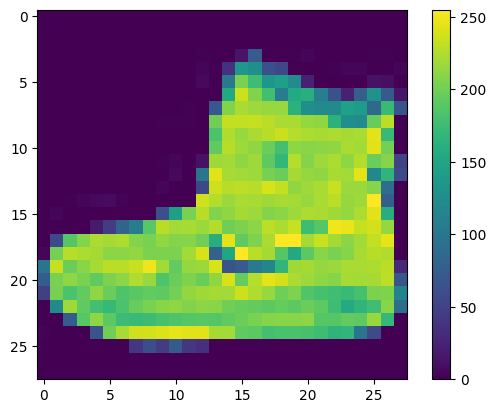

In [15]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)

In [18]:
# Масштабируем эти значения до диапазона от 0 до 1:
train_images = train_images / 255.0
test_images = test_images / 255.0

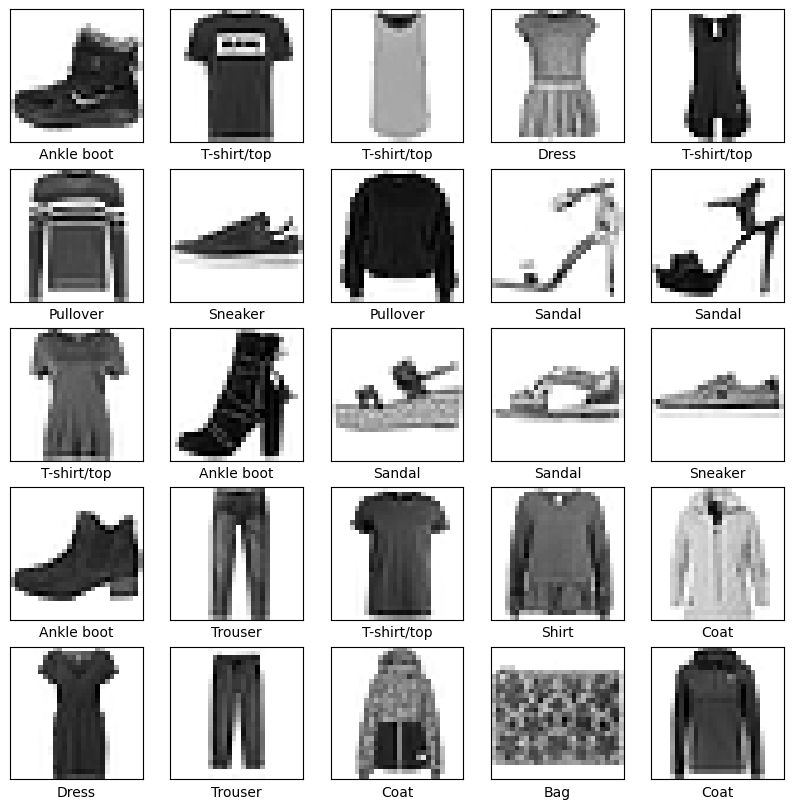

In [21]:
# Выведем на экран 25 изображений из
# обучающей выборки вместе с лейблами:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

In [22]:
# Построение нейронной сети:
model = keras.Sequential([
keras.layers.Flatten(input_shape=(28, 28)),
keras.layers.Dense(128, activation=tf.nn.relu),
keras.layers.Dense(10, activation=tf.nn.softmax)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [24]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [25]:
# Обучение модели нейронной сети
model.fit(train_images, train_labels, epochs=1)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6503 - loss: 1.1066


In [27]:
# Проверка точности работы:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7451 - loss: 0.7281
Test accuracy: 0.7451000213623047


In [28]:
# Получение оценки классов одежды на основе новых изображений:
predictions = model.predict(test_images)
#Здесь полученная модель будет предсказывать класс одежды
# для каждого изображения в проверочном датасете.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [29]:
# Инициируем первую проверку:
predictions[0]

array([1.1349546e-04, 2.6374773e-06, 3.7703852e-04, 3.3879609e-04,
       4.1281822e-04, 3.3688033e-01, 1.1152733e-03, 2.4487142e-01,
       3.7305214e-02, 3.7858298e-01], dtype=float32)

In [30]:
# получим ответ, в каком из своих вариантов нейронная сеть
# больше всего уверена, то есть, какое изображение
# она распознала точнее всего
np.argmax(predictions[0])
test_labels[0]

np.uint8(9)

In [31]:
# пишем функцию для построения диаграмм:
def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format(
        class_names[predicted_label],
        100 * np.max(predictions_array),
        class_names[true_label]
    ), color=color)

def plot_value_array(i, predictions_array, true_label):
    predictions_array, true_label = predictions_array[i], true_label[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    thisplot = plt.bar(range(10), predictions_array, color="#777777")
    plt.ylim([0, 1])

    predicted_label = np.argmax(predictions_array)
    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')

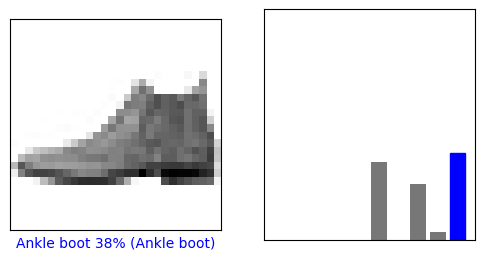

In [32]:
# Далее проверим точность распознавания первого изображения
# из массива (номер 0): (номер изображения i)
i = 0
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions, test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions, test_labels)

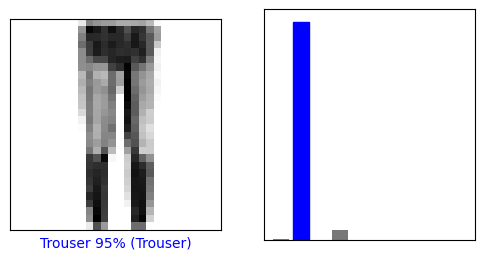

In [33]:
# Можем проверить точность и на другом изображении под номером 3:
i = 3
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions, test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions, test_labels)

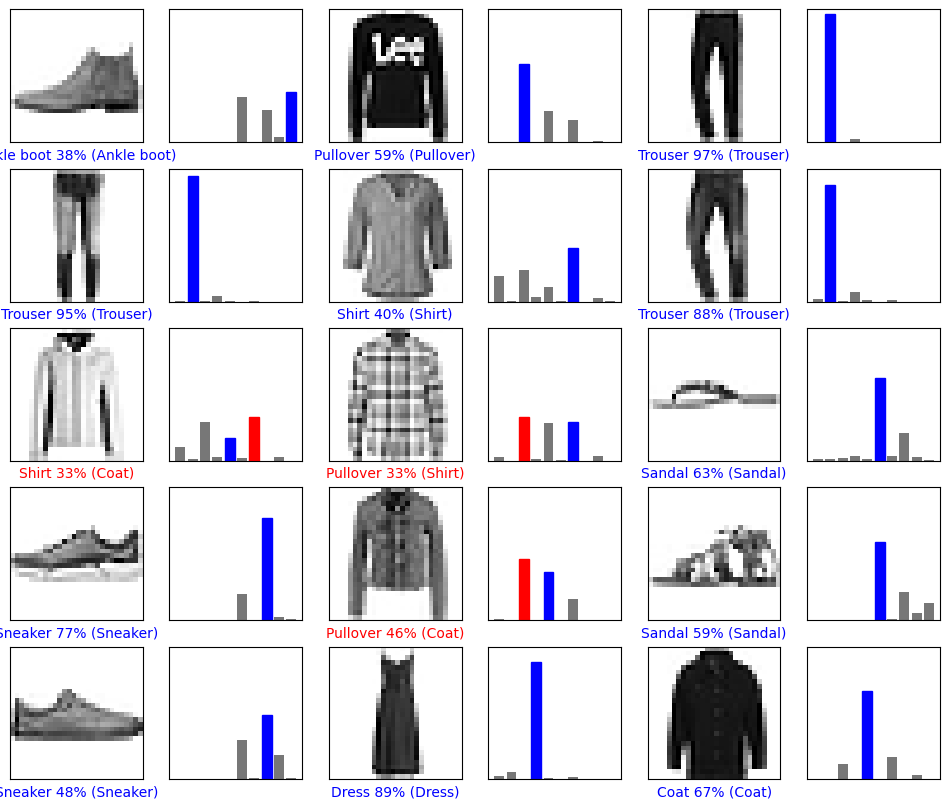

In [35]:
# Также можно вывести на экран сразу несколько изображений:
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))

for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions, test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions, test_labels)

Таким образом мы получили рабочую нейронную сеть, способную распознавать категории одежды по ее изображениям.